# Guided: read three learning curves, then run one cross-validation together

*The row's guided exercise, after chapter 3 and case 1 · also searched as: learning curve
interpretation, k-fold cross validation*

**Your two tasks.** (1) Three mystery models, A, B and C, were trained on the bank's honest feature
set. For each, name the side of the trade it sits on and prescribe one fix. (2) Run one five-fold
cross-validation and report its mean with its spread.

Work in the cells marked **YOUR TURN**. The answer sits in the last cell; scroll to it only after the
room has committed.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


In [2]:
# Load the day's public dataset once; later runs read the cached copy.
import io, zipfile, pathlib, urllib.request
import pandas as pd
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def fetch(url, name):
    path = CACHE / name
    if not path.exists():
        path.write_bytes(urllib.request.urlopen(url, timeout=60).read())
    return path

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0). The zip holds a second zip."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        outer = zipfile.ZipFile(fetch("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
                                      "bank+marketing.zip"))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(f"{len(bank):,} calls, {bank.shape[1]} columns, {bank['y'].eq('yes').mean():.2%} said yes")

41,188 calls, 21 columns, 11.27% said yes


In [3]:
# The week's pipeline: the same columns, the same split and the same baseline every day.
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def engineer(df):
    """Wednesday's fix for pdays: 999 means never contacted, so it becomes a flag plus the real days."""
    df = df.copy()
    df["never_contacted"] = (df["pdays"] == 999).astype(int)
    df["days_since_contact"] = np.where(df["pdays"] == 999, 0, df["pdays"])
    return df

# Wednesday's honest feature set: the customer table, the economy, the pdays flag. No duration.
HONEST = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since_contact"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

bank = engineer(bank)
train, val, test = week_split(bank)          # test stays in the sealed envelope until Friday
X_train, X_val = train[HONEST], val[HONEST]
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)

# pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
NUM = [c for c in HONEST if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in HONEST if c not in NUM]

def prep(scale=True):
    """One-hot the categories; scale the numbers for the linear model (trees do not need it)."""
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

print(f"train {len(train):,}  validation {len(val):,}  test {len(test):,} (sealed)")
print(f"{len(NUM)} number columns and {len(CAT)} category columns")

train 24,712  validation 8,238  test 8,238 (sealed)
10 number columns and 10 category columns


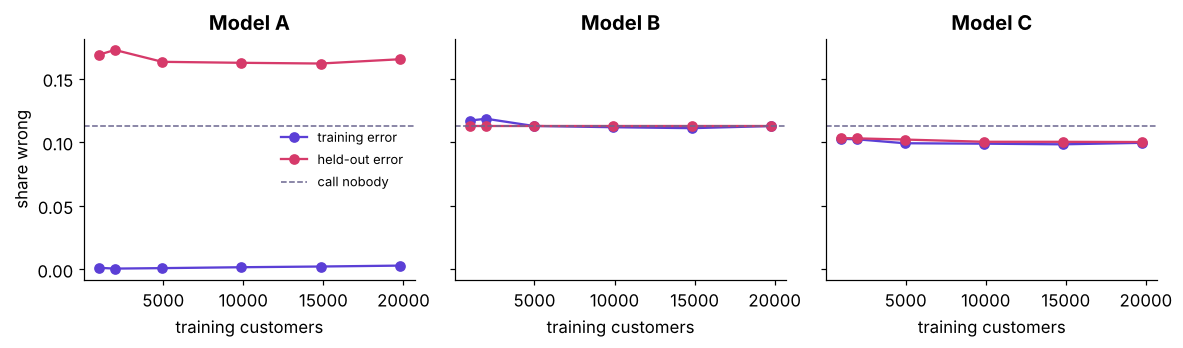

PASS  three mystery models drawn


In [4]:
from sklearn.model_selection import learning_curve, StratifiedKFold
folds = StratifiedKFold(5, shuffle=True, random_state=42)
mystery = {"A": DecisionTreeClassifier(random_state=42),
           "B": DecisionTreeClassifier(max_depth=1, random_state=42),
           "C": LogisticRegression(C=0.1, max_iter=3000)}
curves = {}
for label, model in mystery.items():
    sizes, tr, va = learning_curve(Pipeline([("prep", prep(scale=(label == "C"))), ("model", model)]),
                                   X_train, y_train, cv=folds, scoring="accuracy",
                                   train_sizes=[0.05, 0.1, 0.25, 0.5, 0.75, 1.0])
    curves[label] = (sizes, 1 - tr.mean(axis=1), 1 - va.mean(axis=1))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
for ax, (label, (s, tr, va)) in zip(axes, curves.items()):
    ax.plot(s, tr, "o-", color=VIOLET, label="training error")
    ax.plot(s, va, "o-", color=ROSE, label="held-out error")
    ax.axhline(y_val.mean(), color=MUTED, ls="--", lw=1, label="call nobody")
    ax.set_title(f"Model {label}"); ax.set_xlabel("training customers")
axes[0].set_ylabel("share wrong"); axes[0].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()
check("three mystery models drawn", len(curves) == 3)

## YOUR TURN 1: read each pair

For each model write one of `bias`, `variance` or `about right`, and one fix. Read the gap first, then
the level against the dashed line.

In [5]:
my_reading = {"A": "?", "B": "?", "C": "?"}      # YOUR TURN: bias, variance or about right
my_fix = {"A": "?", "B": "?", "C": "?"}          # YOUR TURN: one fix each, in a few words
for k in my_reading:
    print(f"Model {k}: {my_reading[k]:12s} fix: {my_fix[k]}")

Model A: ?            fix: ?
Model B: ?            fix: ?
Model C: ?            fix: ?


## YOUR TURN 2: one cross-validation, together

Change `k` to 3 and then 10 after the first run, and watch what happens to the spread.

In [6]:
from sklearn.model_selection import cross_val_score
k = 5                                            # YOUR TURN: try 3, then 10
model = Pipeline([("prep", prep()), ("model", LogisticRegression(C=0.1, max_iter=3000))])
cv_scores = cross_val_score(model, X_train, y_train, scoring="roc_auc",
                            cv=StratifiedKFold(k, shuffle=True, random_state=42))
print(f"{k}-fold AUC: mean {cv_scores.mean():.3f}, spread {cv_scores.std():.3f}, folds {cv_scores.round(3)}")
check(f"{k} folds ran and each returned a score", len(cv_scores) == k)

5-fold AUC: mean 0.786, spread 0.013, folds [0.771 0.769 0.798 0.796 0.797]
PASS  5 folds ran and each returned a score


## The answer

Read it after the room has committed to its three calls.

In [7]:
answer = {}
for label, (s, tr, va) in curves.items():
    gap, level = va[-1] - tr[-1], va[-1]
    if gap > 0.05:
        answer[label] = ("variance", "brake it: limit depth or raise min_samples_leaf")
    elif level >= y_val.mean() - 0.005:
        answer[label] = ("bias", "add capacity: more depth or better columns")
    else:
        answer[label] = ("about right", "keep it and compare it with the others on the same folds")
    print(f"Model {label}: gap {gap:.3f}, held-out error {level:.3f} -> {answer[label][0]}: {answer[label][1]}")
print("A is the unlimited tree, B is a one-question stump, C is the braked logistic model.")
check("A carries the variance", answer["A"][0] == "variance")
check("B carries the bias", answer["B"][0] == "bias")

Model A: gap 0.162, held-out error 0.165 -> variance: brake it: limit depth or raise min_samples_leaf
Model B: gap -0.000, held-out error 0.113 -> bias: add capacity: more depth or better columns
Model C: gap 0.001, held-out error 0.100 -> about right: keep it and compare it with the others on the same folds
A is the unlimited tree, B is a one-question stump, C is the braked logistic model.
PASS  A carries the variance
PASS  B carries the bias


**What the interviewer listens for.** You read the gap before the level, you name the fix that matches
the side, and you say what would change your call (for A: if more rows had closed the gap, more data
would be the cheaper fix; on this file it did not).